Filename: C:\Users\aliev\Downloads\level2_2026W31_1B_0480_1D6_spx_l2b-v27-2026-224.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       275   (2040, 2040)   float32   
  2  FLAGS         1 CompImageHDU    185   (2040, 2040)   int32   
  3  VARIANCE      1 ImageHDU       119   (2040, 2040)   float32   
  4  ZODI          1 ImageHDU       122   (2040, 2040)   float32   
  5  EPSF          1 BinTableHDU     56   441R x 11C   [J, J, E, E, E, E, J, E, E, E, 1089D]   
  6  WCS-WAVE      1 BinTableHDU     22   1R x 3C   [9J, 9J, 162E]   
BUNIT: MJy / sr
DETECTOR: 6
DATE: 2026-08-13T00:00:13.566
MJDREF: 0.0
DATE-OBS: 2026-07-29T12:31:00.504
MJD-OBS: 61250.521533611
DATE-BEG: 2026-07-29T12:31:00.504
MJD-BEG: 61250.521533611
DATE-AVG: 2026-07-29T12:31:58.063
MJD-AVG: 61250.5221998
DATE-END: 2026-07-29T12:32:55.621
MJD-END: 61250.52286599
Центр кадра: <SkyCoord (ICRS): (ra, dec) in deg
    (224.13

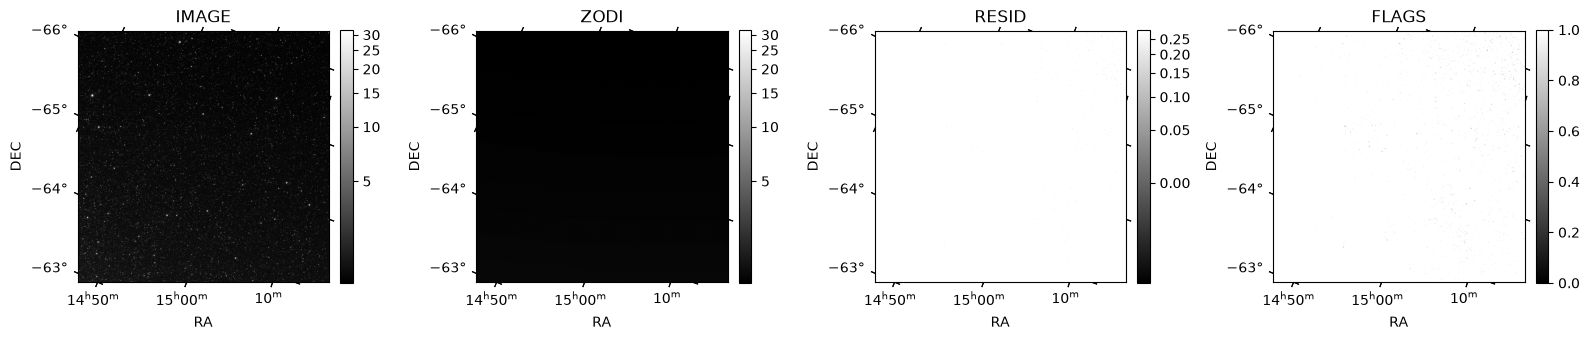

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN-SIP' 'DEC--TAN-SIP'
CUNIT : 'deg' 'deg'
CRVAL : 223.968400986 -65.3795566051
CRPIX : 1020.5 1020.5
PC1_1 PC1_2  : 0.0015752145623 -0.000603933484029
PC2_1 PC2_2  : -0.000669471588036 -0.00159992352303
CDELT : 1.0 1.0
NAXIS : 2040  2040


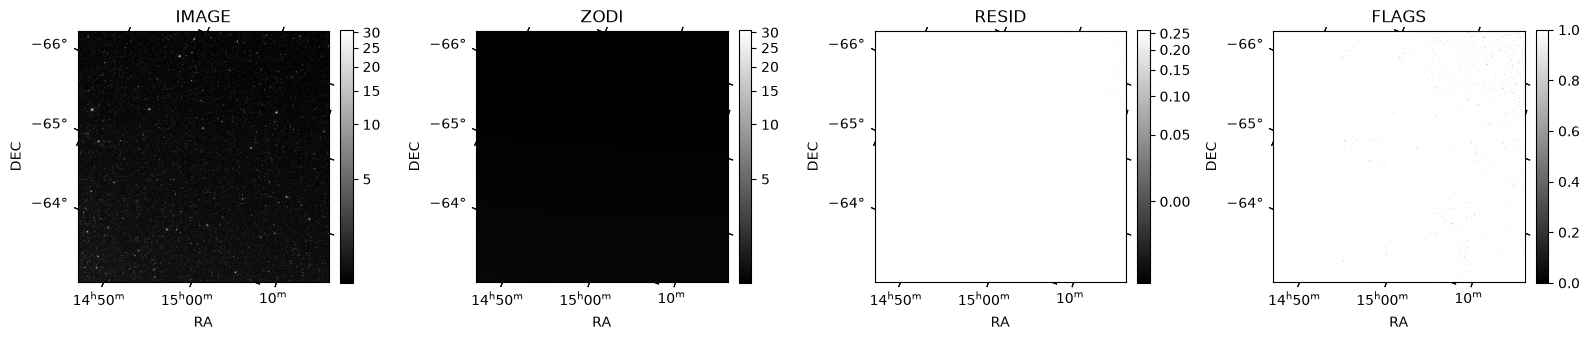

In [21]:
import numpy as np
from astropy.io import fits
from astropy.visualization import AsinhStretch, ImageNormalize, PercentileInterval
import astropy.wcs as wcs

import matplotlib.pyplot as plt

files = [
    r"C:\Users\aliev\Downloads\level2_2026W31_1B_0480_1D6_spx_l2b-v27-2026-224.fits",
    r"C:\Users\aliev\Downloads\level2_2026W31_1B_0480_2D6_spx_l2b-v27-2026-224.fits"]

keywords = ["DATE", "MJD", "BUNIT", "DETECTOR"]

def print_keywords(header, title):
    for key, value in header.items():
        if any(k in key for k in keywords):
            print(f"{key}: {value}")

def load_spherex(path, verbose=True):
    with fits.open(path) as hdul:
        if verbose:
            hdul.info()
            print_keywords(hdul["PRIMARY"].header, "PRIMARY")
            print_keywords(hdul["IMAGE"].header, "IMAGE")

        header = hdul["IMAGE"].header
        image = hdul["IMAGE"].data.astype(float)
        zodi = hdul["ZODI"].data.astype(float)
        flags = hdul["FLAGS"].data
        w = wcs.WCS(header)

    ny, nx = image.shape
    sky_center = w.pixel_to_world(nx // 2, ny // 2)

    if verbose:
        print(f"Центр кадра: {sky_center}\n"
              f"CRVAL: ({header['CRVAL1']}, {header['CRVAL2']})")
    return {"image": image, "zodi": zodi, "flags": flags ,"wcs": w, "unit": header.get("BUNIT", "")}

def show_image(image, zodi, flags, w, unit="", title=""):
    residual = image - zodi
    mask = flags != 0
    residual_masked = np.where(mask, np.nan, residual)

    norm_main = ImageNormalize(image, interval=PercentileInterval(99.5), stretch=AsinhStretch())
    norm_res = ImageNormalize(residual_masked, interval=PercentileInterval(99.5), stretch=AsinhStretch())

    panel = [
        (image, norm_main, "IMAGE"),
        (zodi, norm_main, "ZODI"),
        (residual_masked, norm_res, "RESID"),
        (mask, None, "FLAGS"),
    ]

    fig = plt.figure(figsize = (16, 6))
    for i, (data, norm, label) in enumerate(panel, start=1):
        ax = fig.add_subplot(1, 4, i, projection=w)
        im = ax.imshow(data, norm=norm, cmap="gray", origin="lower")
        ax.set_title(label)

        if w is not None:
            ax.set_xlabel("RA")
            ax.set_ylabel("DEC")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    fig.tight_layout()
    plt.show()

if __name__ == "__main__":
    frames = [load_spherex(f) for f in files]

    for fr in frames:
        print(fr["wcs"])
        show_image(fr["image"], fr["zodi"], fr["flags"], fr["wcs"], unit=fr["unit"])


# for file in files:
#     with fits.open(file) as hdul:
#         hdul.info()
#
#         header = hdul["IMAGE"].header
#         data = hdul["IMAGE"].data
#         data_zodi = hdul["ZODI"].data
#         header_prim = hdul["PRIMARY"].header
#
#
#         for key in header.keys():
#           if "MJD" in key or "DATE" in key or "DETECTOR" in key or "BUNIT" in key:
#               print(f"{key}: {header[key]}")
#         for key in header_prim.keys():
#             if "MJD" in key or "DATE" in key or "DETECTOR" in key or "BUNIT" in key:
#                print(f"{key}: {header_prim[key]}")
#
#         w = wcs.WCS(header)
#         wcs_list.append(w)
#         data_list.append(data)
#         data_list_z.append(data_zodi)
#
#         center = [i // 2 for i in data.shape[::-1]]
#         center_sky = w.pixel_to_world(*center)
#         print(center_sky, header["CRVAL1"], header["CRVAL2"])
#
#     print()
#
# for item in wcs_list:
#      print(item)
#
# def show_image(image, zodi):
#     fig, ax = plt.subplots(1, 3)
#     plt.show()
#
# for data in data_list:
#     p1, p99 = np.nanpercentile(data, [1, 99])
#     norm = ImageNormalize(vmin=p1, vmax=p99, stretch=LogStretch())
#
#     fig, ax = plt.subplots(1, 3)
#     ax[0].imshow(data, norm=norm, cmap="plasma", origin="lower")
#     plt.show()
#
# for data in data_list_z:
# plt.imshow(data, norm=norm, cmap="plasma", origin="lower")
# plt.colorbar(label="Brightness")
# plt.show()